In [1]:
#import cell
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from prettytable import PrettyTable
from utils import stats, exploration_plots
from preprocessing import preprocessing

**importing the data**

In [2]:
df = pd.read_csv("development.csv", header = "infer")
evaluate_df = pd.read_csv("evaluation.csv", header = "infer")

In [5]:
y = df["price"]
df = df.drop(columns="price")
# Encode all categorical columns
# categorical_cols = df.select_dtypes(include=['object', 'category']).columns
# X_encoded = pd.get_dummies(df, columns=categorical_cols)
# X_test_encoded = pd.get_dummies(evaluate_df,columns=categorical_cols)

In [6]:
# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.2, random_state=42)

**Starting the data cleaning**

In [10]:
missing_per_feature_dev = X_train.isnull().sum()
print(missing_per_feature_dev)

category        0
bathrooms       0
bedrooms        0
fee             0
has_photo       0
pets_allowed    0
square_feet     0
cityname        0
state           0
latitude        0
longitude       0
source          0
time            0
id              0
dtype: int64


In [11]:
# missing_per_feature = df.isnull().sum()
# print(missing_per_feature)

missing_per_feature_eval = X_test.isnull().sum()
print(missing_per_feature_eval)

category        0
bathrooms       3
bedrooms        2
fee             0
has_photo       0
pets_allowed    0
square_feet     0
cityname        0
state           0
latitude        0
longitude       0
source          0
time            0
id              0
dtype: int64


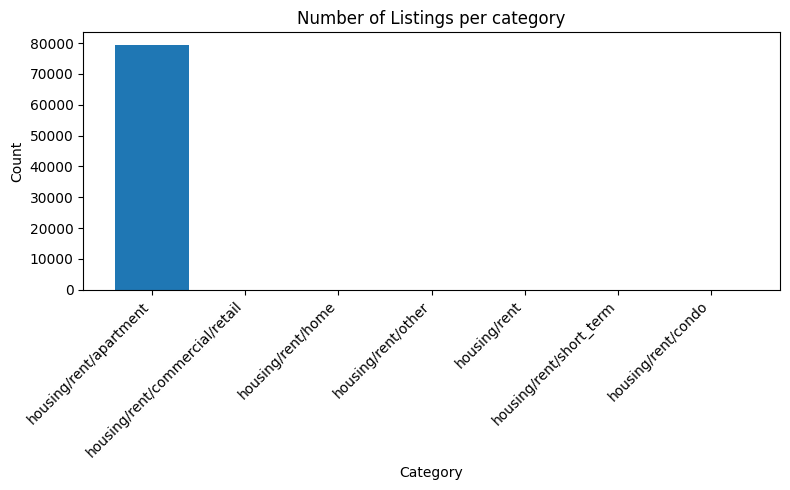

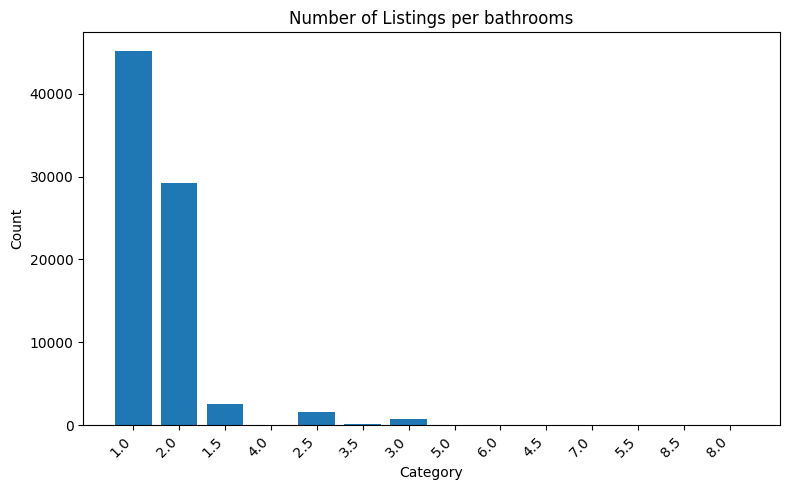

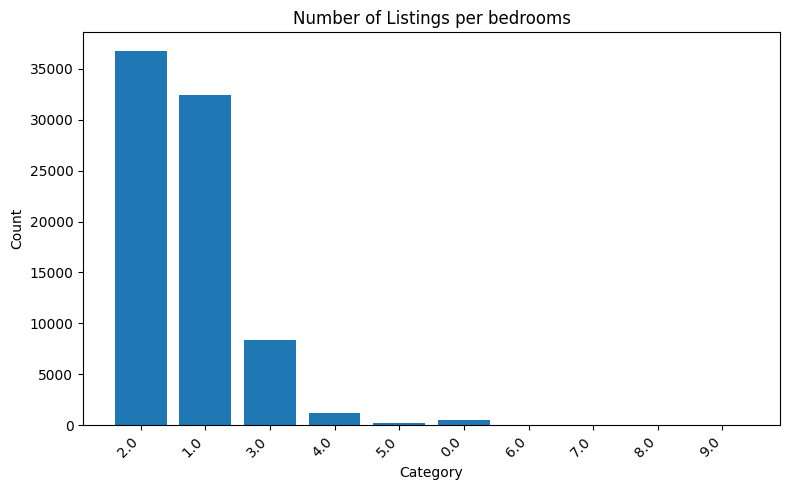

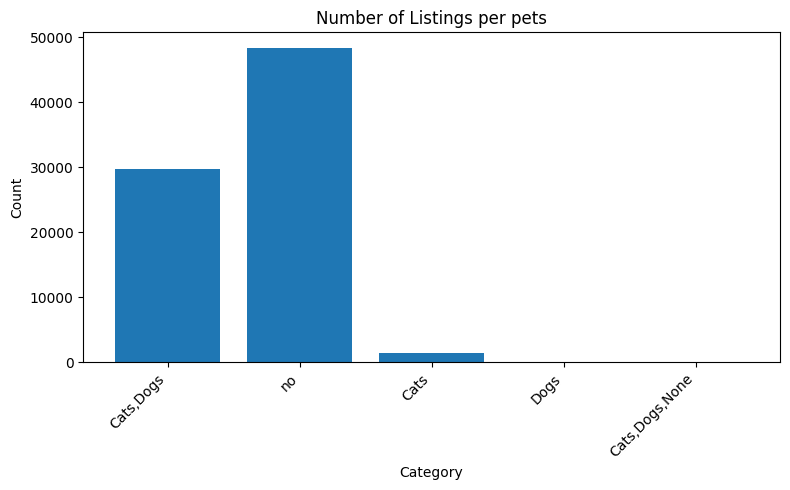

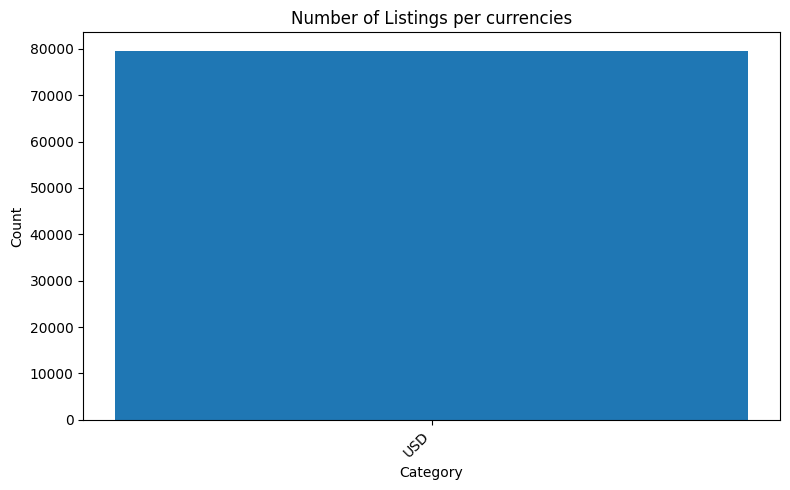

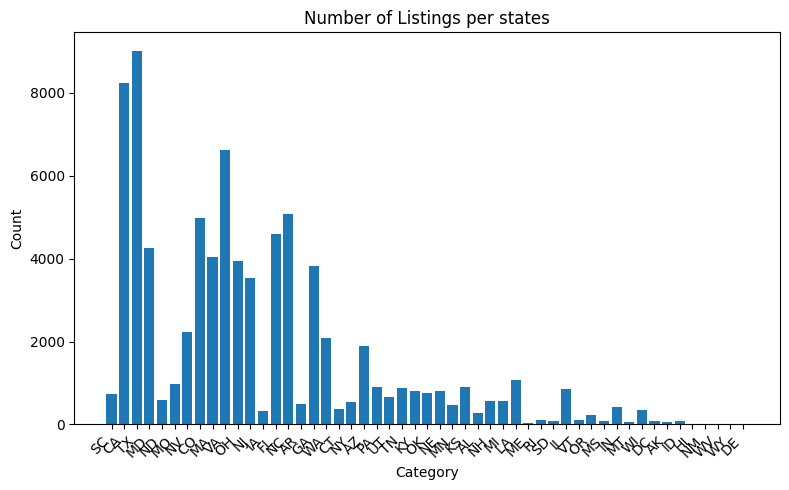

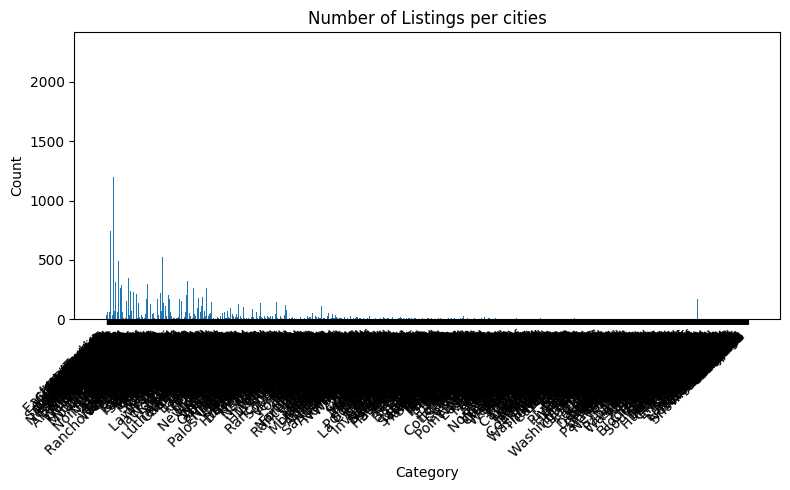

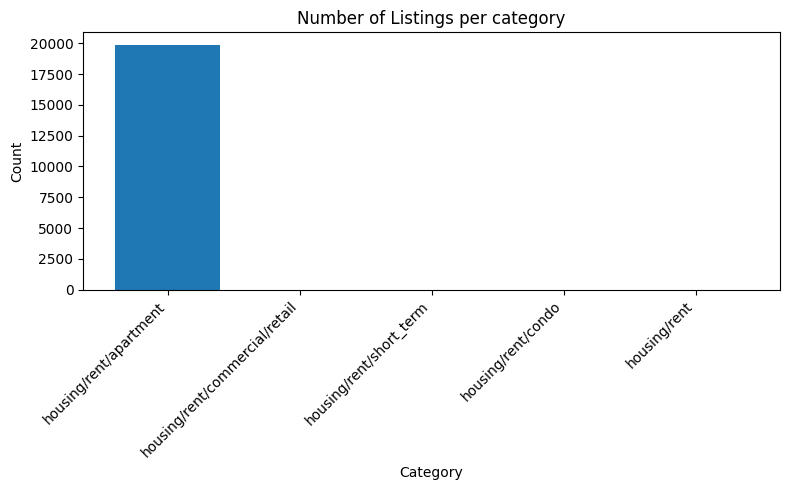

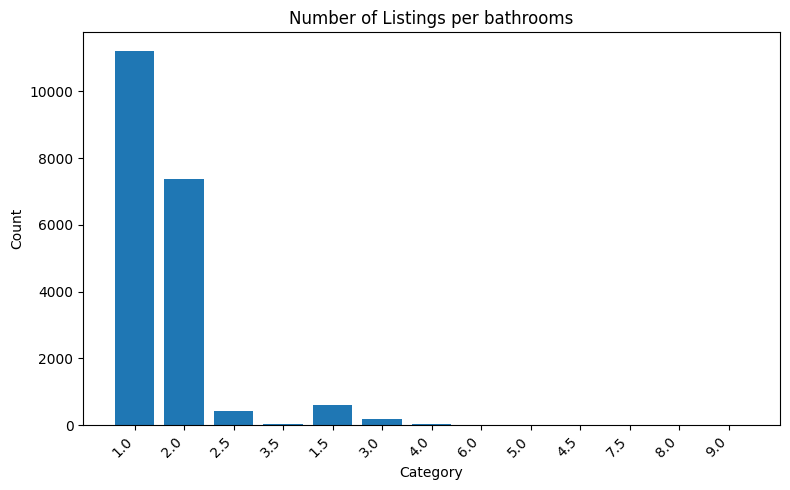

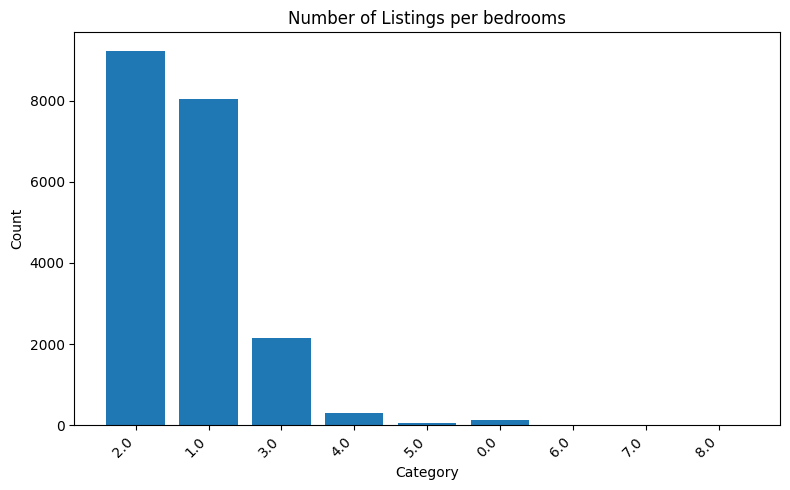

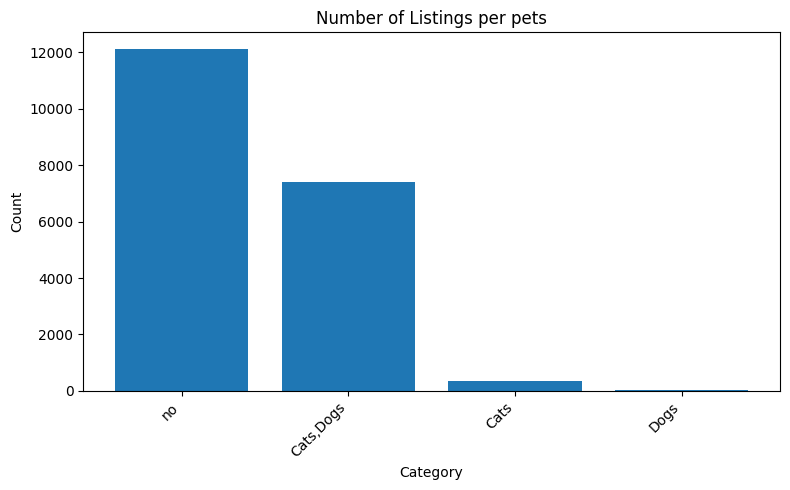

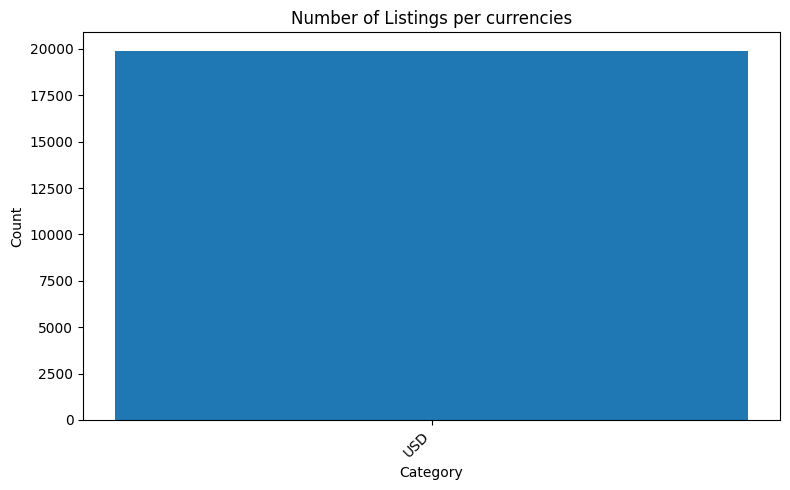

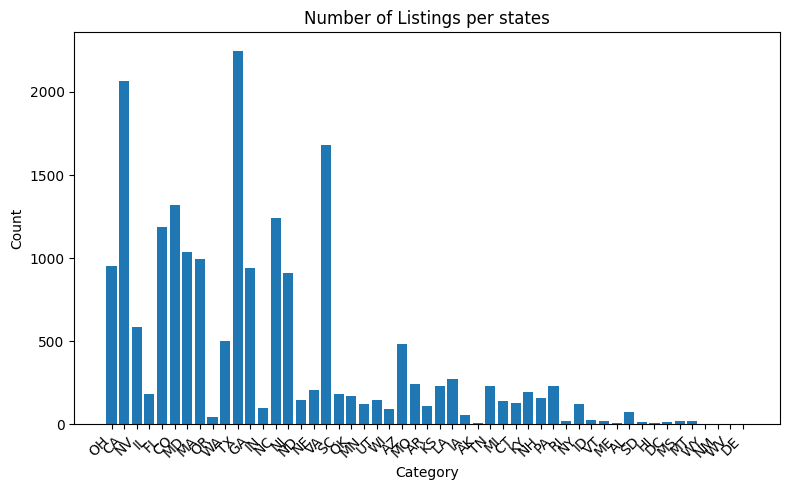

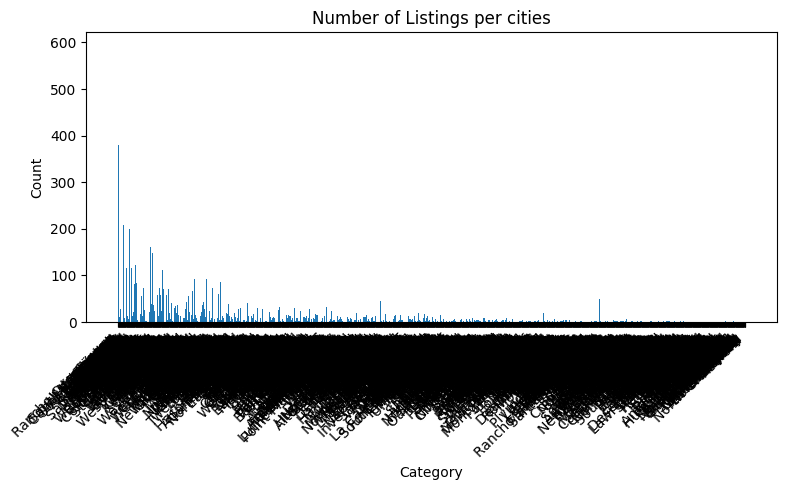

In [5]:
stats(df)
stats(evaluate_df)
#now i want to explore the relationships between the features and the price:

In [ ]:
from collections import Counter

cities = Counter(df["cityname"])
states = Counter(df["state"])
print(cities)
print(states)
print(df["cityname"].nunique())
print(df[""])

dict_keys(['Taylors', 'Los Angeles', 'Euless', 'Elkridge', 'Bismarck', 'Kansas City', 'Henderson', 'Littleton', 'East Weymouth', 'Denver', 'Alexandria', 'Cincinnati', 'Castle Rock', 'Kearny', 'Middletown', 'Chatham', 'Council Bluffs', 'Richmond', 'Virginia Beach', 'Tampa', 'Davis', 'Raleigh', 'Austin', 'Jersey City', 'Fayetteville', 'Norfolk', 'Folsom', 'Jamestown', 'Parkersburg', 'Orlando', 'Atlanta', 'Woodinville', 'Fort Worth', 'Cliffwood', 'Charlotte', 'Bloomfield', 'Rochester', 'Petersburg', 'Las Vegas', 'Pasadena', 'Toledo', 'Florissant', 'Midlothian', 'Avondale', 'Williamsburg', 'Philadelphia', 'North Royalton', 'Salt Lake City', 'South Weymouth', 'Guilderland', 'Hyattsville', 'Hermosa Beach', 'Cleveland', 'El Cajon', 'Pittsburgh', 'Antioch', 'Duncanville', 'Coppell', 'Glen Allen', 'Hopkinsville', 'Gaithersburg', 'Reno', 'South Pasadena', 'Carrollton', 'Lynnwood', 'Irving', 'Miami', 'Dallas', 'Hurst', 'Arlington', 'Redlands', 'Clifton Park', 'Newton Highlands', 'Neptune City', '

In [ ]:
features = ["bathrooms", "bedrooms", "has_photo", "pets_allowed", "square_feet", "time", "state"]
exploration_plots(df, features)
exploration_plots(evaluate_df,features)

Text(0.5, 1.0, 'square_feet vs Price (Scatter)')

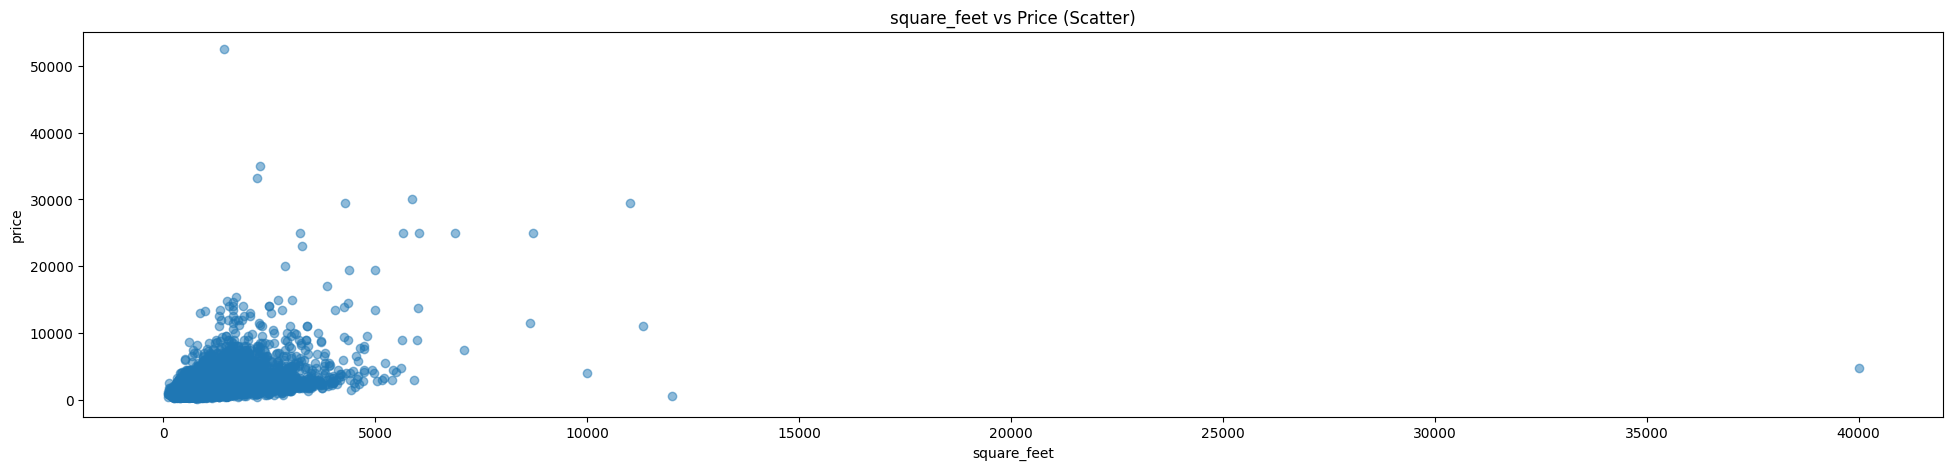

In [4]:
plt.figure(figsize=(24, 5))
plt.scatter(df["square_feet"], df["price"], alpha=0.5)
plt.xlabel("square_feet")
plt.ylabel("price")
plt.title(f"square_feet vs Price (Scatter)")

In [9]:
X_train, X_test = preprocessing(X_train, X_test)

Missing values in train set, columns latitude: 0
Missing values in train set, columns longitude: 0
Missing values in test set, columns latitude: 0
Missing values in test set, columns longitude: 0
Bins means:                   bathrooms  bedrooms
size_bin                             
(149.999, 604.0]   1.011545  1.240970
(604.0, 699.0]     1.012621  1.114924
(699.0, 752.0]     1.014680  1.138230
(752.0, 816.0]     1.043394  1.222654
(816.0, 898.0]     1.151557  1.477048
(898.0, 978.0]     1.461064  1.811618
(978.0, 1060.0]    1.699112  1.973043
(1060.0, 1142.0]   1.867307  2.060537
(1142.0, 1260.0]   1.914897  2.190767
(1260.0, 1696.0]   1.996175  2.581448
Bins: [ 150.  604.  699.  752.  816.  898.  978. 1060. 1142. 1260. 1696.]


/Users/giulianaparadiso/Desktop/PoliTo/Data science lab/Progetto/data-science-lab-project/utils.py:122: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_means = df_filtered.groupby('size_bin')[cols_to_impute].mean()


Missing values in train set, columns bathrooms: 0
Missing values in train set, columns bedrooms: 0
Missing values in test set, columns bathrooms: 3
Missing values in test set, columns bedrooms: 2


In [ ]:
# Separate features and target
table = PrettyTable()

rfr = RandomForestRegressor()
rfr.fit(X_train, y_train)
y_pred = rfr.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
table.field_names = ["Model", "MAE"]
table.add_row(["Random Forest", mae])
print(table)


ValueError: could not convert string to float: 'housing/rent/apartment'

In [45]:
importances = rfr.feature_importances_
feature_names = X_train.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)
print(feat_imp.head(50))  # Show top 20 most important features

AttributeError: 'RandomForestRegressor' object has no attribute 'estimators_'

In [ ]:
rfr_online = RandomForestRegressor()
rfr_online.fit(df,y)
# Align columns of X_test_encoded to X_encoded
X_test_encoded = evaluate_df.reindex(columns=X_encoded.columns, fill_value=0)
# Now you can safely predict
y_pred = rfr_online.predict(X_test_encoded)
results_df = pd.DataFrame({
    "Id": range(len(y_pred)),
    "Predicted": y_pred.astype(float)  # or round if you want integers
})

# Save to CSV
results_df.to_csv("predictions.csv", index=False)


In [ ]:
#c97d8bd8e2dcfa84c1e1c72140d1582f23e136d1ba0fd19d8a39915e7db6207e

In [ ]:
importances = rfr_online.feature_importances_
feature_names = X_train.columns
feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)
print(feat_imp.head(20))  # Show top 20 most important features

square_feet                   0.266545
longitude                     0.173329
state_CA                      0.126574
latitude                      0.095876
time                          0.064465
bathrooms                     0.051090
bedrooms                      0.037882
id                            0.030605
cityname_New York             0.010329
cityname_West Hollywood       0.009030
cityname_Barstow              0.008231
cityname_Snowmass Village     0.007861
state_WA                      0.006992
state_CO                      0.006944
cityname_Pacific Palisades    0.006764
cityname_Jersey City          0.004632
cityname_Glasco               0.003661
has_photo_Thumbnail           0.003435
state_CT                      0.003245
cityname_Chicago              0.003113
dtype: float64


da fare
- assegnazioni valori a bathrooms and bedrooms
- distribuzione stati nel dataset (evaluation e train)
- gestire i campi title e body con tf-Idf
